# Практичне заняття № 2 — Дерево рішень і ліс дерев рішень

**Завдання.** Застосувати алгоритми дерева рішень та лісу дерев рішень до
датасетів з підбірки [Kaggle: security](https://www.kaggle.com/datasets?search=security),
проаналізувати переваги та недоліки алгоритмів і зробити висновки щодо якості
класифікації різних даних **залежно від особливостей даних у датасетах**.

Оскільки завдання вимагає висновків про залежність якості від особливостей даних,
роботу побудовано як **порівняння трьох датасетів однаковим конвеєром аналізу**.
Це дозволяє приписати різницю в результатах саме властивостям даних, а не
відмінностям у методиці.

| | UGRansome | NSL-KDD | Intrusion 2025 |
|---|---|---|---|
| Записів | 149 043 | 25 192 | 9 537 |
| Ознак | 13 | 39 | 9 |
| Класів | 3 (`S`/`A`/`SS`) | 2 (`normal`/`anomaly`) | 2 (`0`/`1`) |
| Домен | трафік вимагачів | мережеві вторгнення | сесії доступу |
| Тип ознак | переважно категоріальні | змішані | змішані, є пропуски |

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Кількість колонок перевіряється одразу: Kaggle
# може оновити версію набору, і краще впасти тут, ніж мовчки отримати інші
# числа, ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл усередині набору, очікувано колонок)
DATASETS = [
    ('ugransome.csv', 'nkongolo/ugransome-dataset',
     'final(2).csv', 14),
    ('nslkdd.csv', 'sampadab17/network-intrusion-detection',
     'Train_data.csv', 42),
    ('intrusion2025.csv', 'dnkumars/cybersecurity-intrusion-detection-dataset',
     'cybersecurity_intrusion_data.csv', 11),
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols):
    import pandas as pd
    got = pd.read_csv(path, nrows=1).shape[1]
    if got != ncols:
        raise ValueError(f"{path.name}: очікували {ncols} колонок, отримали {got}")


def _ensure(local, slug, member, ncols):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)


на місці: data/ugransome.csv (10.0 МБ)
на місці: data/nslkdd.csv (2.9 МБ)
на місці: data/intrusion2025.csv (0.7 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

## 1. Завантаження обох датасетів єдиним конвеєром

In [3]:
SPECS = {
    "UGRansome":      {"path": "data/ugransome.csv",    "target": "Prediction",      "drop": []},
    "NSL-KDD":        {"path": "data/nslkdd.csv",       "target": "class",           "drop": []},
    "Intrusion 2025": {"path": "data/intrusion2025.csv","target": "attack_detected", "drop": ["session_id"]},
}

def load(spec):
    # Єдина підготовка для всіх датасетів: прибираємо ідентифікатори та
    # константні колонки, кодуємо категоріальні цілими числами.
    # Масштабування деревам не потрібне.
    df = pd.read_csv(spec["path"])
    y = df[spec["target"]].copy()
    X = df.drop(columns=[spec["target"]] + spec["drop"]).copy()

    const = X.columns[X.nunique() <= 1].tolist()
    X = X.drop(columns=const)

    # рахуємо пропуски ДО кодування: cat.codes перетворює NaN на -1,
    # і після цього isna() вже нічого не знайде
    n_missing = int(X.isna().sum().sum())

    cats = X.select_dtypes(include=["object", "string"]).columns.tolist()
    for col in cats:
        # cat.codes дає -1 для пропусків — для дерева це окрема категорія «невідомо»,
        # що коректніше за підстановку середнього чи моди
        X[col] = X[col].astype("category").cat.codes
    X = X.fillna(-1)
    return df, X, y, const, cats, n_missing

DATA = {}
for name, spec in SPECS.items():
    df, X, y, const, cats, n_missing = load(spec)
    DATA[name] = {"df": df, "X": X, "y": y}
    print(f"=== {name} ===")
    print(f"  розмір: {X.shape[0]} × {X.shape[1]}   класи: {dict(y.value_counts())}")
    print(f"  базова лінія: {y.value_counts(normalize=True).max():.4f}")
    print(f"  видалено ідентифікаторів: {spec['drop'] or '—'}")
    print(f"  видалено константних: {const or '—'}")
    print(f"  категоріальних закодовано: {cats}")
    print(f"  пропущених значень оброблено: {n_missing}")

=== UGRansome ===
  розмір: 149043 × 13   класи: {'S': np.int64(66380), 'A': np.int64(42561), 'SS': np.int64(40102)}
  базова лінія: 0.4454
  видалено ідентифікаторів: —
  видалено константних: —
  категоріальних закодовано: ['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress', 'Threats']
  пропущених значень оброблено: 0
=== NSL-KDD ===
  розмір: 25192 × 39   класи: {'normal': np.int64(13449), 'anomaly': np.int64(11743)}
  базова лінія: 0.5339
  видалено ідентифікаторів: —
  видалено константних: ['num_outbound_cmds', 'is_host_login']
  категоріальних закодовано: ['protocol_type', 'service', 'flag']
  пропущених значень оброблено: 0
=== Intrusion 2025 ===
  розмір: 9537 × 9   класи: {0: np.int64(5273), 1: np.int64(4264)}
  базова лінія: 0.5529
  видалено ідентифікаторів: ['session_id']
  видалено константних: —
  категоріальних закодовано: ['protocol_type', 'encryption_used', 'browser_type']
  пропущених значень оброблено: 1966


## 2. Перевірка на витік даних

Урок практичного заняття № 1: перш ніж довіряти високій точності, треба
виключити витік. Перевіряємо дублікати (той самий запис і в навчальній, і в
тестовій вибірці) та колонки, що самі по собі визначають мітку.

In [4]:
for name, d in DATA.items():
    df, X, y = d["df"], d["X"], d["y"]
    print(f"=== {name} ===")
    print(f"  повних дублікатів рядків: {df.duplicated().sum()}")
    print(f"  дублікатів за ознаками:   {X.duplicated().sum()} ({X.duplicated().mean():.2%})")
    # найнебезпечніші — категоріальні колонки з великою чистотою
    worst = []
    for col in X.columns:
        if X[col].nunique() > 100:
            continue
        ct = pd.crosstab(X[col], y)
        purity = ct.max(axis=1) / ct.sum(axis=1)
        share_pure = ct.sum(axis=1)[purity > 0.99].sum() / len(X)
        worst.append((col, purity.mean(), share_pure))
    worst.sort(key=lambda t: -t[2])
    print("  найсильніші одиночні колонки (частка рядків у 'чистих' категоріях):")
    for col, p, s in worst[:3]:
        print(f"    {col:22} середня чистота={p:.3f}  частка в чистих={s:.1%}")
    print()

=== UGRansome ===


  повних дублікатів рядків: 0
  дублікатів за ознаками:   392 (0.26%)


  найсильніші одиночні колонки (частка рядків у 'чистих' категоріях):
    SeddAddress            середня чистота=0.683  частка в чистих=10.5%
    Clusters               середня чистота=0.767  частка в чистих=6.6%
    Family                 середня чистота=0.596  частка в чистих=0.1%

=== NSL-KDD ===
  повних дублікатів рядків: 0
  дублікатів за ознаками:   1 (0.00%)


  найсильніші одиночні колонки (частка рядків у 'чистих' категоріях):
    diff_srv_rate          середня чистота=0.870  частка в чистих=29.1%
    dst_host_srv_serror_rate середня чистота=0.813  частка в чистих=27.6%
    dst_host_serror_rate   середня чистота=0.774  частка в чистих=27.0%

=== Intrusion 2025 ===
  повних дублікатів рядків: 0
  дублікатів за ознаками:   0 (0.00%)
  найсильніші одиночні колонки (частка рядків у 'чистих' категоріях):
    failed_logins          середня чистота=0.831  частка в чистих=16.6%
    login_attempts         середня чистота=0.826  частка в чистих=10.9%
    protocol_type          середня чистота=0.562  частка в чистих=0.0%



Дублікатів немає в жодному датасеті (для NSL-KDD це очікувано — усунення
дублікатів KDD'99 було головною метою його створення).

У Intrusion 2025 видалено `session_id` — унікальний ідентифікатор сесії, який не
несе інформації про атаку. Увага: колонки `session_duration` та
`ip_reputation_score` теж майже унікальні, але це **неперервні числові ознаки**,
для яких це нормально, і видаляти їх не можна.

Проте в NSL-KDD колонка `service` помітно сильніша за будь-яку колонку UGRansome:
близько чверті рядків потрапляє в категорії, де мітка визначена однозначно. Це не
витік у строгому сенсі, але означає, що **частину задачі можна розв'язати одним
запитом до однієї ознаки**. Це знадобиться для пояснення результатів.

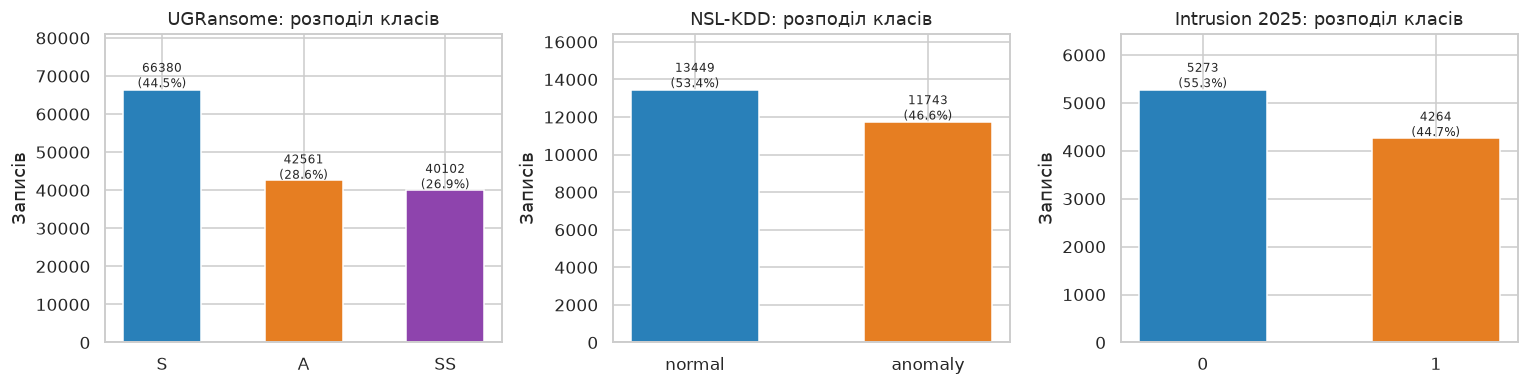

In [5]:
# --- Рисунок 1: баланс класів в обох датасетах ---
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (name, d) in zip(axes, DATA.items()):
    vc = d["y"].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=["#2980b9", "#e67e22", "#8e44ad"][:len(vc)], width=0.55)
    ax.set_title(f"{name}: розподіл класів")
    ax.set_ylabel("Записів")
    for i, v in enumerate(vc.values):
        ax.text(i, v * 1.01, f"{v}\n({v/len(d['y']):.1%})", ha="center", fontsize=8)
    ax.set_ylim(0, vc.max() * 1.22)
plt.tight_layout()
plt.savefig(ASSETS / "01-class-balance.png", bbox_inches="tight")
plt.show()

## 3. Дерево рішень: вплив глибини

Глибина — головний параметр дерева. Мілке дерево недонавчається, глибоке
перенавчається. Будуємо криву валідації для обох датасетів.

In [6]:
depths = [1, 2, 3, 5, 7, 10, 15, 20, 30, None]
labels = [str(d) if d is not None else "∞" for d in depths]

depth_results = {}
for name, d in DATA.items():
    X, y = d["X"], d["y"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
                                          random_state=RANDOM_STATE, stratify=y)
    d["split"] = (Xtr, Xte, ytr, yte)
    tr, va = [], []
    for dep in depths:
        t = DecisionTreeClassifier(max_depth=dep, random_state=RANDOM_STATE).fit(Xtr, ytr)
        tr.append(t.score(Xtr, ytr))
        va.append(cross_val_score(t, Xtr, ytr, cv=3, scoring="accuracy").mean())
    depth_results[name] = (tr, va)
    print(f"{name}: найкраща валідаційна точність {max(va):.4f} при глибині {labels[int(np.argmax(va))]}")

UGRansome: найкраща валідаційна точність 0.9947 при глибині 15


NSL-KDD: найкраща валідаційна точність 0.9952 при глибині 10


Intrusion 2025: найкраща валідаційна точність 0.8960 при глибині 7


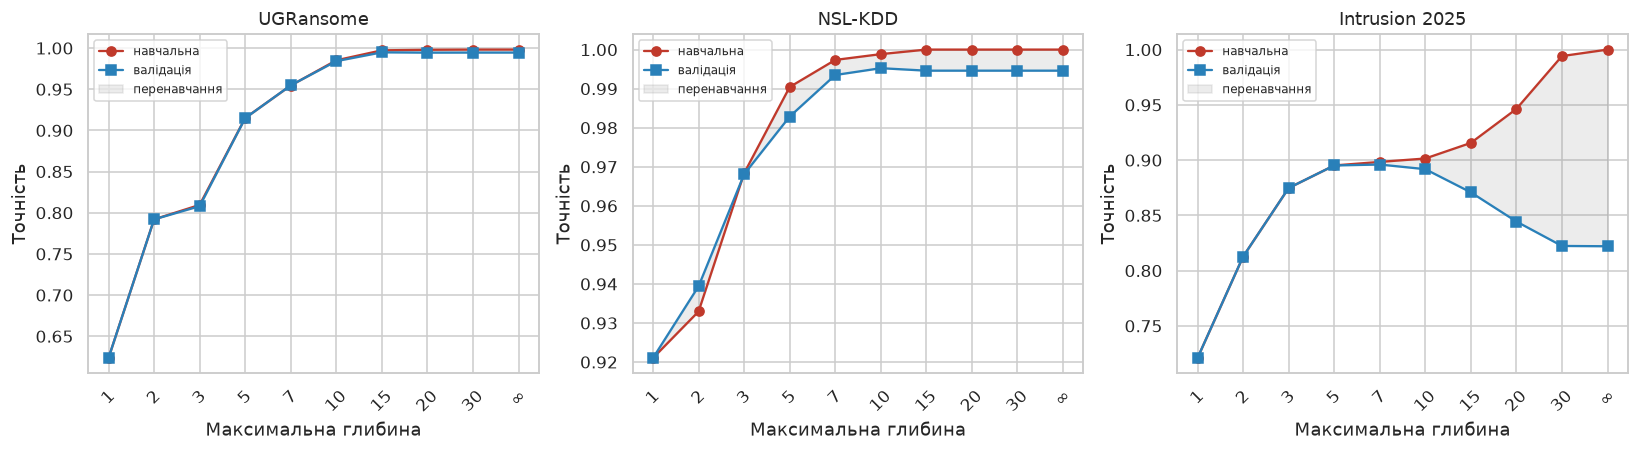

In [7]:
# --- Рисунок 2: криві валідації ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, (tr, va)) in zip(axes, depth_results.items()):
    xs = range(len(depths))
    ax.plot(xs, tr, "o-", label="навчальна", color="#c0392b")
    ax.plot(xs, va, "s-", label="валідація", color="#2980b9")
    ax.fill_between(xs, va, tr, alpha=0.15, color="gray", label="перенавчання")
    ax.set_xticks(list(xs)); ax.set_xticklabels(labels, rotation=45)
    ax.set_xlabel("Максимальна глибина"); ax.set_ylabel("Точність")
    ax.set_title(f"{name}"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "02-depth-curves.png", bbox_inches="tight")
plt.show()

In [8]:
# Мілке (інтерпретоване) та повне дерево для кожного датасету
for name, d in DATA.items():
    Xtr, Xte, ytr, yte = d["split"]
    shallow = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(Xtr, ytr)
    full = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtr, ytr)
    d["shallow"], d["full"] = shallow, full
    print(f"{name}:")
    print(f"  max_depth=5   вузлів={shallow.tree_.node_count:5}  тест={shallow.score(Xte, yte):.4f}")
    print(f"  без обмежень  вузлів={full.tree_.node_count:5}  тест={full.score(Xte, yte):.4f}  "
          f"глибина={full.get_depth()}")

UGRansome:
  max_depth=5   вузлів=   55  тест=0.9156
  без обмежень  вузлів= 1465  тест=0.9935  глибина=26


NSL-KDD:
  max_depth=5   вузлів=   47  тест=0.9889
  без обмежень  вузлів=  193  тест=0.9943  глибина=13
Intrusion 2025:
  max_depth=5   вузлів=   13  тест=0.8834
  без обмежень  вузлів= 1739  тест=0.8159  глибина=36


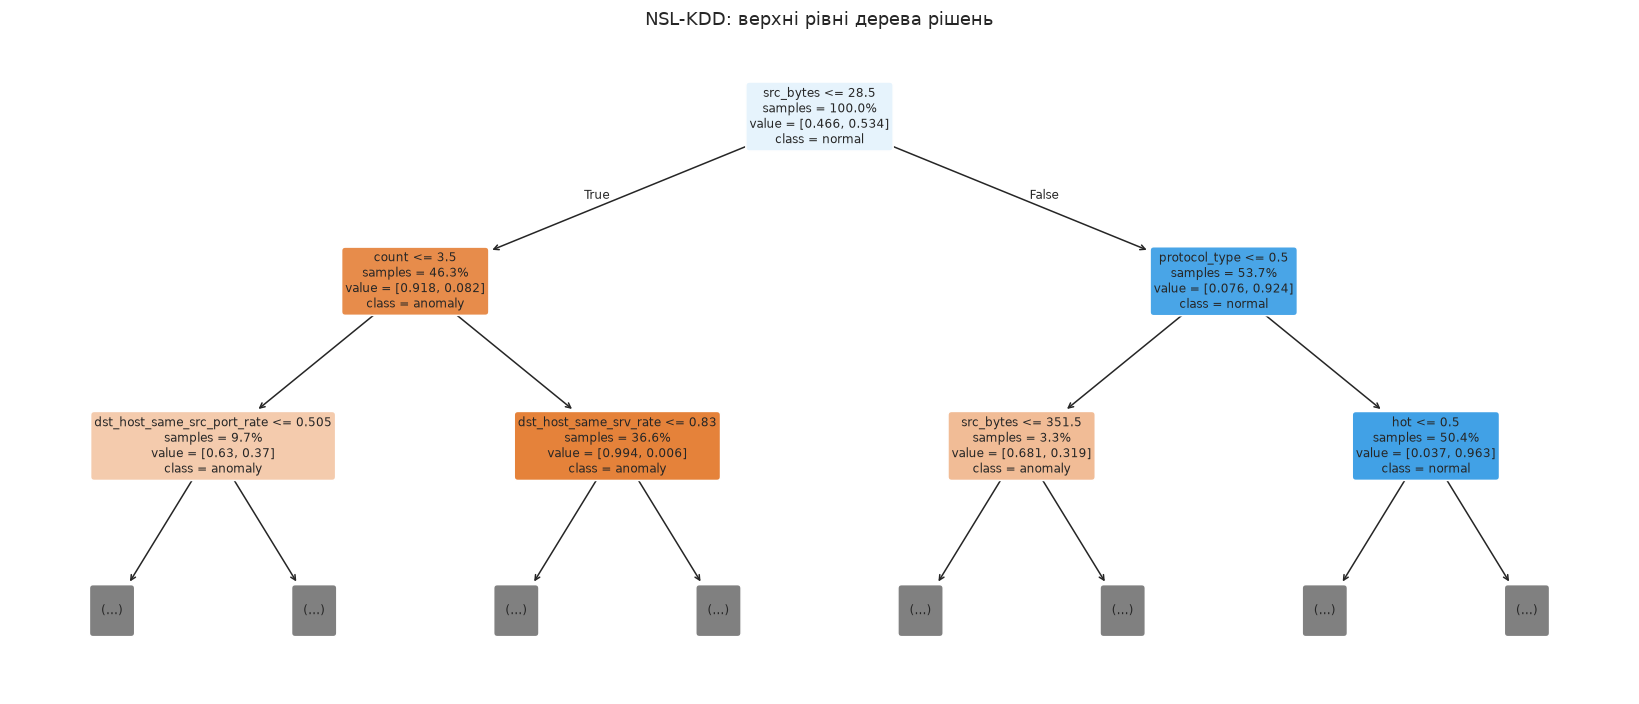

In [9]:
# --- Рисунок 3: верхні рівні дерева для NSL-KDD ---
d = DATA["NSL-KDD"]
fig, ax = plt.subplots(figsize=(15, 6.5))
plot_tree(d["shallow"], max_depth=2, feature_names=d["X"].columns,
          class_names=d["shallow"].classes_, filled=True, rounded=True,
          fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title("NSL-KDD: верхні рівні дерева рішень", fontsize=12)
plt.tight_layout()
plt.savefig(ASSETS / "03-tree-nslkdd.png", bbox_inches="tight")
plt.show()

## 4. Порівняння методів на обох датасетах

In [10]:
def models():
    return {
        "Логістична регресія": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
        "Дерево (max_depth=5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        "Дерево (без обмежень)": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Ліс (100 дерев)": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    }

rows = []
for name, d in DATA.items():
    X, y = d["X"], d["y"]
    Xtr, Xte, ytr, yte = d["split"]
    base = y.value_counts(normalize=True).max()
    rows.append({"Датасет": name, "Модель": "Базова лінія", "Точність (CV)": base,
                 "Ст. відх.": 0.0, "F1-macro": 0.0})
    for mname, m in models().items():
        s = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
        m.fit(Xtr, ytr)
        rows.append({"Датасет": name, "Модель": mname, "Точність (CV)": s.mean(),
                     "Ст. відх.": s.std(),
                     "F1-macro": f1_score(yte, m.predict(Xte), average="macro")})

comparison = pd.DataFrame(rows)
comparison.to_csv("data/results-summary.csv", index=False)
comparison.pivot(index="Модель", columns="Датасет", values="Точність (CV)").round(4)

Датасет,Intrusion 2025,NSL-KDD,UGRansome
Модель,,,
Базова лінія,0.5529,0.5339,0.4454
Дерево (max_depth=5),0.8922,0.9788,0.9151
Дерево (без обмежень),0.8120,0.9959,0.9943
Логістична регресія,0.7338,0.9541,0.7423
Ліс (100 дерев),0.8928,0.9975,0.9934


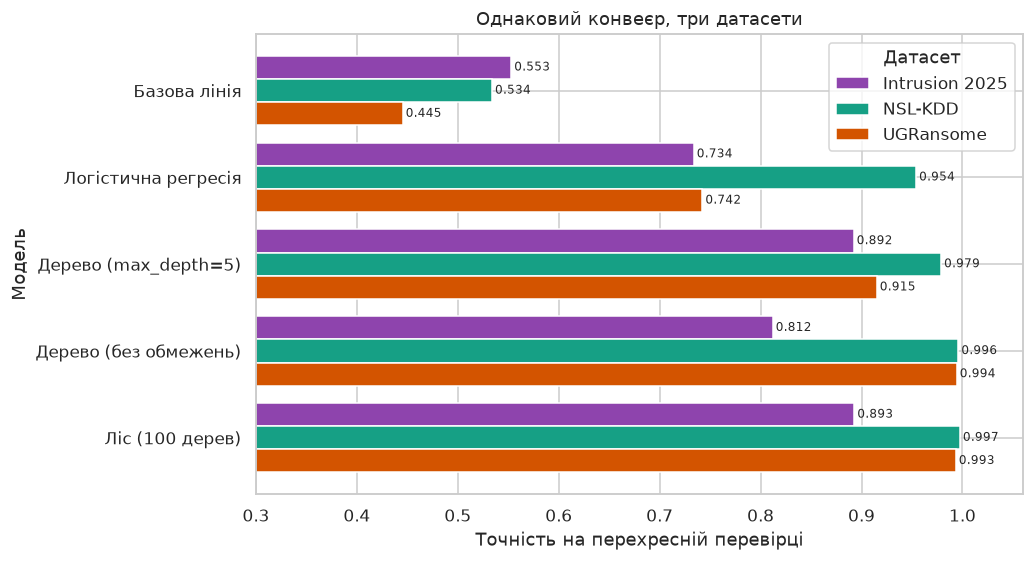

Розрив «лінійна модель → дерево»:
  UGRansome    0.7423 → 0.9943   (+0.2521)
  NSL-KDD      0.9541 → 0.9959   (+0.0418)
  Intrusion 2025 0.7338 → 0.8120   (+0.0782)

Різниця «ліс − повне дерево»:
  UGRansome    -0.0009
  NSL-KDD      +0.0015
  Intrusion 2025 +0.0808


In [11]:
# --- Рисунок 4: порівняння методів пліч-о-пліч ---
piv = comparison.pivot(index="Модель", columns="Датасет", values="Точність (CV)")
order = ["Базова лінія", "Логістична регресія", "Дерево (max_depth=5)",
         "Дерево (без обмежень)", "Ліс (100 дерев)"]
piv = piv.loc[order]

fig, ax = plt.subplots(figsize=(9.5, 5.2))
piv.plot.barh(ax=ax, color=["#8e44ad", "#16a085", "#d35400"], width=0.8)
ax.set_xlim(0.3, 1.06)
ax.set_xlabel("Точність на перехресній перевірці")
ax.set_title("Однаковий конвеєр, три датасети")
ax.invert_yaxis()
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(ASSETS / "04-comparison.png", bbox_inches="tight")
plt.show()

print("Розрив «лінійна модель → дерево»:")
for name in DATA:
    lr = piv.loc["Логістична регресія", name]
    tr = piv.loc["Дерево (без обмежень)", name]
    print(f"  {name:12} {lr:.4f} → {tr:.4f}   (+{tr-lr:.4f})")
print("\nРізниця «ліс − повне дерево»:")
for name in DATA:
    print(f"  {name:12} {piv.loc['Ліс (100 дерев)', name] - piv.loc['Дерево (без обмежень)', name]:+.4f}")

## 5. Важливість ознак

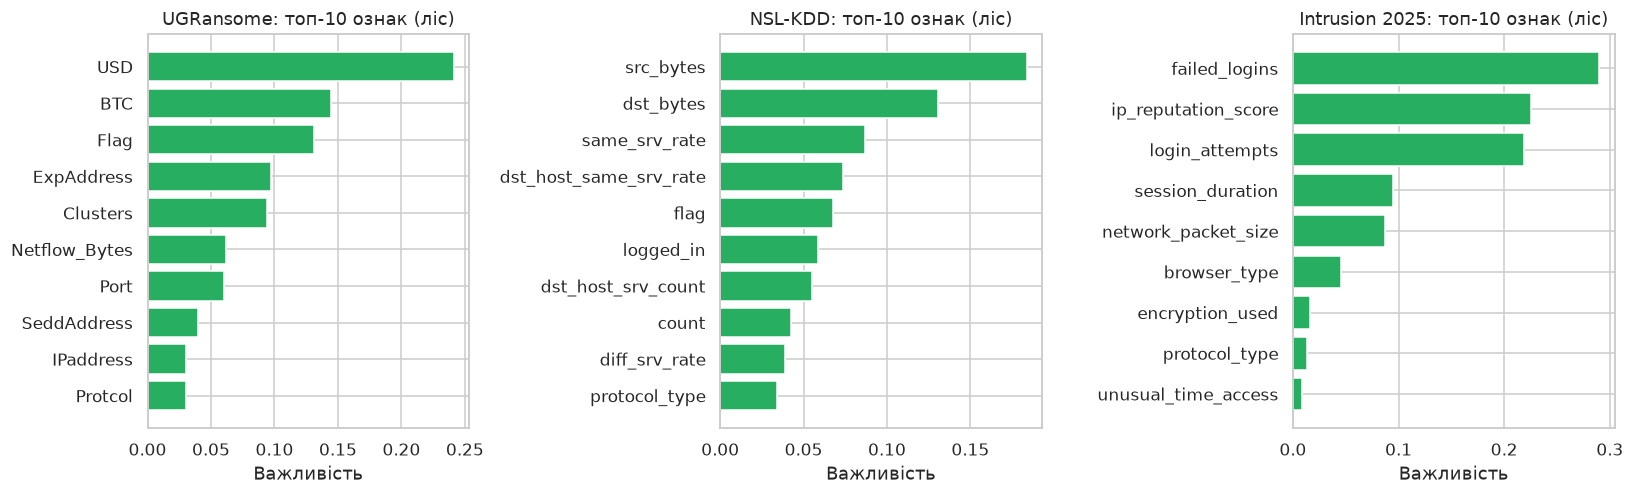

UGRansome: топ-3 ознаки сумарно дають 51.7% важливості
NSL-KDD: топ-3 ознаки сумарно дають 40.1% важливості
Intrusion 2025: топ-3 ознаки сумарно дають 73.4% важливості


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (name, d) in zip(axes, DATA.items()):
    Xtr, Xte, ytr, yte = d["split"]
    forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE,
                                    n_jobs=-1).fit(Xtr, ytr)
    d["forest"] = forest
    imp = pd.Series(forest.feature_importances_, index=d["X"].columns)
    imp = imp.sort_values(ascending=False).head(10)[::-1]
    ax.barh(imp.index, imp.values, color="#27ae60")
    ax.set_title(f"{name}: топ-10 ознак (ліс)")
    ax.set_xlabel("Важливість")
plt.tight_layout()
plt.savefig(ASSETS / "05-importance.png", bbox_inches="tight")
plt.show()

for name, d in DATA.items():
    imp = pd.Series(d["forest"].feature_importances_, index=d["X"].columns).sort_values(ascending=False)
    print(f"{name}: топ-3 ознаки сумарно дають {imp.head(3).sum():.1%} важливості")

## 6. Коли ансамбль справді допомагає?

На двох датасетах із трьох ліс майже не перевершує повне дерево — але на
третьому перевершує помітно. Гіпотеза: ансамбль
бореться з **дисперсією**, а коли залежність детермінована й без шуму, гасити
немає чого. Перевіряємо керованим експериментом — додаємо шум до міток і
дивимось, як змінюється перевага лісу.

In [13]:
rng = np.random.RandomState(RANDOM_STATE)
noise_levels = [0.0, 0.05, 0.10, 0.20, 0.30]
noise_rows = []

for name, d in DATA.items():
    X, y = d["X"], d["y"]
    n = min(25000, len(X))
    idx = rng.choice(len(X), n, replace=False)
    Xs, ys = X.iloc[idx].reset_index(drop=True), y.iloc[idx].reset_index(drop=True)
    classes = ys.unique()
    for lvl in noise_levels:
        yn = ys.copy()
        if lvl > 0:
            flip = rng.rand(len(yn)) < lvl
            yn[flip] = rng.choice(classes, flip.sum())
        t = cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE),
                            Xs, yn, cv=3, scoring="accuracy").mean()
        f = cross_val_score(RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE,
                                                   n_jobs=-1), Xs, yn, cv=3, scoring="accuracy").mean()
        noise_rows.append({"Датасет": name, "Шум": lvl, "Дерево": t, "Ліс": f, "Перевага лісу": f - t})

noise_df = pd.DataFrame(noise_rows)
noise_df.to_csv("data/noise-experiment.csv", index=False)
noise_df.pivot(index="Шум", columns="Датасет", values="Перевага лісу").round(4)

Датасет,Intrusion 2025,NSL-KDD,UGRansome
Шум,,,
0.00,0.0744,0.0015,-0.0001
0.05,0.0890,0.0289,0.0373
0.10,0.1047,0.0549,0.0624
0.20,0.1166,0.0821,0.0972
0.30,0.1258,0.0996,0.1095


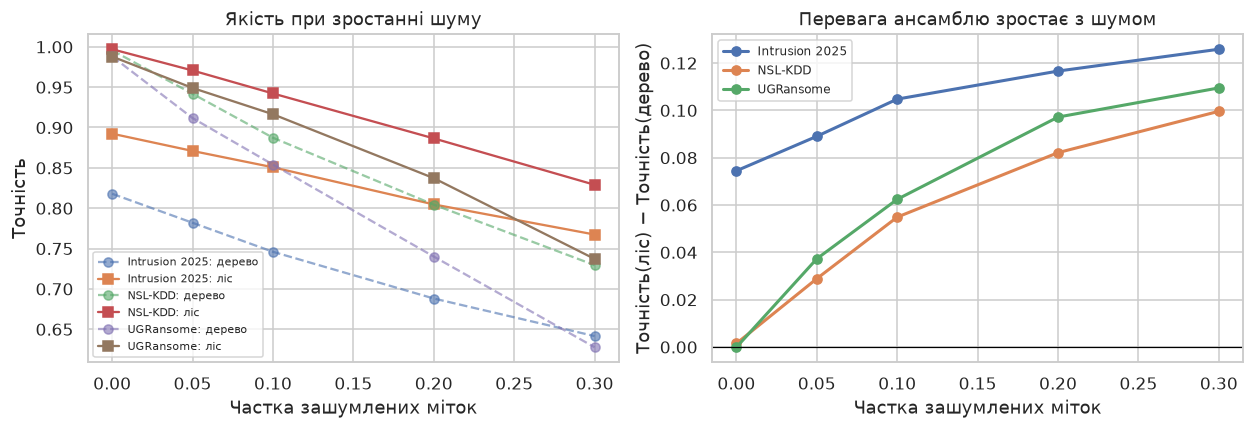

In [14]:
# --- Рисунок 6: перевага ансамблю проти шуму ---
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for name, grp in noise_df.groupby("Датасет"):
    axes[0].plot(grp["Шум"], grp["Дерево"], "o--", alpha=0.6, label=f"{name}: дерево")
    axes[0].plot(grp["Шум"], grp["Ліс"], "s-", label=f"{name}: ліс")
    axes[1].plot(grp["Шум"], grp["Перевага лісу"], "o-", label=name, linewidth=2)
axes[0].set_xlabel("Частка зашумлених міток"); axes[0].set_ylabel("Точність")
axes[0].set_title("Якість при зростанні шуму"); axes[0].legend(fontsize=7)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Частка зашумлених міток")
axes[1].set_ylabel("Точність(ліс) − Точність(дерево)")
axes[1].set_title("Перевага ансамблю зростає з шумом"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "06-noise.png", bbox_inches="tight")
plt.show()

## 7. Матриці невідповідностей

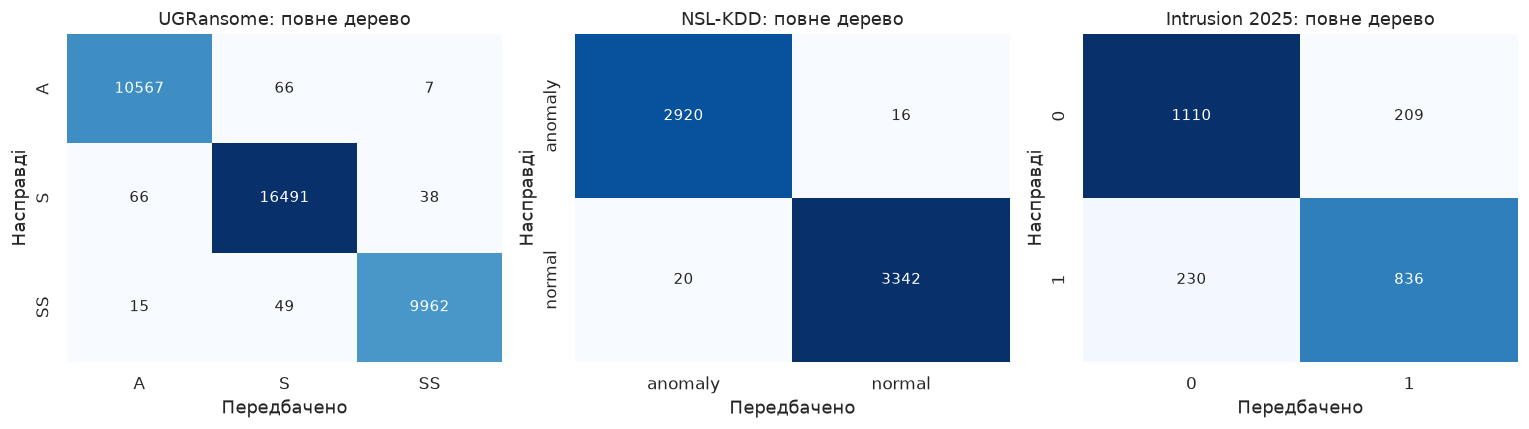

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, d) in zip(axes, DATA.items()):
    Xtr, Xte, ytr, yte = d["split"]
    m = d["full"]
    cm = confusion_matrix(yte, m.predict(Xte), labels=m.classes_)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=m.classes_, yticklabels=m.classes_)
    ax.set_title(f"{name}: повне дерево")
    ax.set_xlabel("Передбачено"); ax.set_ylabel("Насправді")
plt.tight_layout()
plt.savefig(ASSETS / "07-confusion.png", bbox_inches="tight")
plt.show()

## 8. Підсумок

In [16]:
print(comparison.pivot(index="Модель", columns="Датасет", values="Точність (CV)").round(4).to_markdown())
print()
print(noise_df.pivot(index="Шум", columns="Датасет", values="Перевага лісу").round(4).to_markdown())

| Модель                |   Intrusion 2025 |   NSL-KDD |   UGRansome |
|:----------------------|-----------------:|----------:|------------:|
| Базова лінія          |           0.5529 |    0.5339 |      0.4454 |
| Дерево (max_depth=5)  |           0.8922 |    0.9788 |      0.9151 |
| Дерево (без обмежень) |           0.812  |    0.9959 |      0.9943 |
| Логістична регресія   |           0.7338 |    0.9541 |      0.7423 |
| Ліс (100 дерев)       |           0.8928 |    0.9975 |      0.9934 |

|   Шум |   Intrusion 2025 |   NSL-KDD |   UGRansome |
|------:|-----------------:|----------:|------------:|
|  0    |           0.0744 |    0.0015 |     -0.0001 |
|  0.05 |           0.089  |    0.0289 |      0.0373 |
|  0.1  |           0.1047 |    0.0549 |      0.0624 |
|  0.2  |           0.1166 |    0.0821 |      0.0972 |
|  0.3  |           0.1258 |    0.0996 |      0.1095 |
